# Experimento aislado: cuotas de consenso y corrección sobre el mercado
**Estado:** prueba exploratoria. No modifica ningún dataset, notebook ni resultado del informe; no está incorporada al informe, la presentación ni el README.

**Pregunta:** ¿se puede mejorar sobre "solo cuotas de Bet365" (68,6 % de accuracy, log-loss 0,598) usando (1) mejores probabilidades del mercado y (2) un modelo que solo aprenda una corrección pequeña sobre ellas?

## Variantes (declaradas antes de ver resultados)
| Id | Descripción |
|---|---|
| **M0** | Referencia: regresión logística sobre las 3 probabilidades de Bet365 (margen quitado de forma proporcional). Es "Solo cuotas" del informe. |
| **M1** | Consenso: promedio de las probabilidades de las casas disponibles entre {B365, BW, IW, PS, VC, WH} (margen proporcional por casa), + regresión logística. |
| **M2** | Igual que M1 pero quitando el margen con el método de **Shin** (modela apuestas de personas informadas). |
| **M3** | Probabilidades del cierre de Pinnacle (`PSC`), proporcional. Solo 2017/18–2024/25 (la fuente no trae cierre en 2025/26). Es información más tardía (justo antes del partido). |
| **M5** *(exploratoria, agregada después de ver M1–M2)* | Promedio de mercado que publica la fuente (`Avg`, o `BbAv` en 2017–2019): promedia ~30 casas, a diferencia de M1, que solo pudo usar 2 a 6. |
| **M6** *(exploratoria, agregada después)* | Pinnacle de apertura (`PS`): separa el efecto de "mejor casa" del de "cuota de cierre" de M3. |
| **M4** | **Corrección sobre el mercado:** regresión logística donde el logit de M2 entra casi sin penalización y las 28 variables del proyecto entran con regularización fuerte (C elegido por validación interna). Si hay información extra en esas variables, debería aparecer aquí. |

## Protocolo
- Validación de ventana expansiva en 7 folds (2018/19–2024/25), igual que el informe, más 2025/26 como confirmación aparte (modelos entrenados con 2017–2025).
- Hiperparámetros por validación interna cronológica (`TimeSeriesSplit(3)`, log-loss). Sin ajuste sobre la temporada de prueba.
- **Métrica principal:** log-loss (calidad de la probabilidad). Secundarias: accuracy y ROC-AUC.
- **Criterio de mejora (fijado antes):** una variante mejora a M0 solo si (i) su log-loss promedio es menor en más de 0,002, (ii) lo es en al menos 5 de 7 folds (si no tiene los 7, en al menos 5 de los disponibles) y (iii) la prueba de Wilcoxon pareada sobre el log-loss por partido da p < 0,05.

## 1. Cuotas de varias casas (football-data.co.uk)

In [1]:
import os, sys, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import wilcoxon
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss

sys.path.insert(0, 'soccerdata')
from scrape_matches import TEAM_NAME_MAP
sns.set_theme(style='whitegrid', palette='muted'); plt.rcParams['figure.dpi'] = 120
os.makedirs('Imagenes/experimento_cuotas', exist_ok=True)
TARGET = 'target_home_win'
RAW = 'Dataset/experimento_cuotas/raw/'
SEL = [c for c in pd.read_csv('Dataset/model_dataset_selected.csv', nrows=1).columns if c not in (TARGET, 'season')]
BOOKS = ['B365', 'BW', 'IW', 'PS', 'VC', 'WH']

def shin(q):
    # q: odds inversas (n,3). Devuelve probabilidades sin margen por el método de Shin (1993), z por bisección.
    S = q.sum(1, keepdims=True); out = np.empty_like(q)
    for i in range(len(q)):
        qi, s = q[i], S[i, 0]; lo, hi = 0.0, 0.4
        for _ in range(60):
            z = (lo + hi) / 2; p = (np.sqrt(z * z + 4 * (1 - z) * qi ** 2 / s) - z) / (2 * (1 - z))
            lo, hi = (z, hi) if p.sum() > 1 else (lo, z)
        out[i] = p / p.sum()
    return out

filas = []
for a in list(range(17, 25)) + [25]:
    code_ = f'{a}{a + 1}'; df = pd.read_csv(RAW + f'E0_{code_}.csv', encoding='latin-1', on_bad_lines='skip').dropna(subset=['HomeTeam', 'FTHG'])
    season = f'20{a}-20{a + 1}'
    r = pd.DataFrame({'season': season, 'home': df.HomeTeam.replace(TEAM_NAME_MAP).values, 'away': df.AwayTeam.replace(TEAM_NAME_MAP).values})
    props, shins, usadas = [], [], []
    for b in BOOKS:
        c = [b + 'H', b + 'D', b + 'A']
        if all(x in df.columns for x in c) and df[c].notna().all(1).mean() > .9:
            q = 1 / df[c].values.astype(float); props.append(q / q.sum(1, keepdims=True)); usadas.append(b)
            ok = ~np.isnan(q).any(1); s_ = np.full_like(q, np.nan); s_[ok] = shin(q[ok]); shins.append(s_)
    r[['cons_h', 'cons_d', 'cons_a']] = np.nanmean(props, axis=0); r[['shin_h', 'shin_d', 'shin_a']] = np.nanmean(shins, axis=0)
    if 'PSCH' in df.columns and df.PSCH.notna().mean() > .9:
        q = 1 / df[['PSCH', 'PSCD', 'PSCA']].values.astype(float); r[['psc_h', 'psc_d', 'psc_a']] = q / q.sum(1, keepdims=True)
    else:
        r[['psc_h', 'psc_d', 'psc_a']] = np.nan
    ca = ['BbAvH', 'BbAvD', 'BbAvA'] if 'AvgH' not in df.columns else ['AvgH', 'AvgD', 'AvgA']
    q = 1 / df[ca].values.astype(float); r[['avg_h', 'avg_d', 'avg_a']] = q / q.sum(1, keepdims=True)
    q = 1 / df[['PSH', 'PSD', 'PSA']].values.astype(float); r[['ps_h', 'ps_d', 'ps_a']] = q / q.sum(1, keepdims=True)
    r['n_casas'] = len(usadas); filas.append(r); print(season, 'casas usadas:', usadas)
ODDS = pd.concat(filas, ignore_index=True)
en = pd.read_csv('Dataset/prueba_2025_26/model_dataset_enriched.csv')
D = en.merge(ODDS, on=['season', 'home', 'away'], how='left', validate='one_to_one')
assert D.cons_h.notna().all() and len(D) == len(en), D.cons_h.isna().sum()
# control: la probabilidad proporcional de Bet365 reconstruida aquí coincide con la del proyecto
print(f'Partidos: {len(D)} | casas por partido: {D.n_casas.value_counts().to_dict()}')
print('Diferencia media |consenso - Bet365| en P(local): %.4f' % (D.cons_h - D.odds_home_prob).abs().mean())

2017-2018 casas usadas: ['B365', 'BW', 'IW', 'PS', 'VC', 'WH']


2018-2019 casas usadas: ['B365', 'BW', 'IW', 'PS', 'VC', 'WH']


2019-2020 casas usadas: ['B365', 'BW', 'IW', 'PS', 'VC', 'WH']


2020-2021 casas usadas: ['B365', 'BW', 'IW', 'PS', 'VC', 'WH']


2021-2022 casas usadas: ['B365', 'BW', 'IW', 'PS', 'VC', 'WH']


2022-2023 casas usadas: ['B365', 'BW', 'IW', 'PS', 'VC', 'WH']


2023-2024 casas usadas: ['B365', 'BW', 'PS', 'VC', 'WH']


2024-2025 casas usadas: ['B365', 'PS']


2025-2026 casas usadas: ['B365', 'BW']
Partidos: 3350 | casas por partido: {6: 2220, 2: 754, 5: 376}
Diferencia media |consenso - Bet365| en P(local): 0.0227


## 2. Entrenamiento y evaluación por fold

In [2]:
seasons = sorted(D.season.unique())
def lr_cv(Xtr, ytr, Xte, grid, scale=True):
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)) if scale else LogisticRegression(max_iter=3000)
    g = GridSearchCV(pipe, {'logisticregression__C': grid}, cv=TimeSeriesSplit(3), scoring='neg_log_loss', n_jobs=-1).fit(Xtr, ytr)
    return g.predict_proba(Xte)[:, 1], g.best_params_['logisticregression__C']

def logit(p): p = np.clip(p, 1e-4, 1 - 1e-4); return np.log(p / (1 - p))
K = 50.0   # el logit del mercado entra multiplicado por K: su penalización efectiva es ~K^2 veces menor que la de las demás variables

def correccion(tr, te, base):
    ztr, zte = logit(tr[base + '_h']).values, logit(te[base + '_h']).values
    sc = StandardScaler().fit(tr[SEL]); Xtr = np.column_stack([K * ztr, sc.transform(tr[SEL])]); Xte = np.column_stack([K * zte, sc.transform(te[SEL])])
    g = GridSearchCV(LogisticRegression(max_iter=5000), {'C': [1e-5, 1e-4, 1e-3, 1e-2]}, cv=TimeSeriesSplit(3), scoring='neg_log_loss', n_jobs=-1).fit(Xtr, tr[TARGET])
    return g.predict_proba(Xte)[:, 1], g.best_params_['C']

variantes = {'M0': ['odds_home_prob', 'odds_draw_prob', 'odds_away_prob'], 'M1': ['cons_h', 'cons_d', 'cons_a'], 'M2': ['shin_h', 'shin_d', 'shin_a'], 'M3': ['psc_h', 'psc_d', 'psc_a'], 'M5': ['avg_h', 'avg_d', 'avg_a'], 'M6': ['ps_h', 'ps_d', 'ps_a']}
GR = [0.01, 0.1, 1, 10, 100]
preds, info = [], []
for k in range(len(seasons) - 1):
    tr = D[D.season.isin(seasons[:k + 1])].sort_values('date'); te = D[D.season == seasons[k + 1]].copy()
    for v, cols in variantes.items():
        if te[cols].isna().any().any(): te['p_' + v] = np.nan; continue
        te['p_' + v], C_ = lr_cv(tr[cols], tr[TARGET], te[cols], GR);
    te['p_M4'], c4 = correccion(tr, te, 'shin'); info.append({'fold': k + 1, 'C_M4': c4})
    te['fold'] = k + 1; preds.append(te[['season', 'home', 'away', TARGET, 'fold'] + [c for c in te.columns if c.startswith('p_M')]])
    print(f'fold {k + 1} ({seasons[k + 1]}) listo | C de la corrección: {c4}')
PALL = pd.concat(preds, ignore_index=True); PALL.to_csv('resultados/experimento_cuotas_predicciones.csv', index=False)
P = PALL[PALL.fold <= 7].copy()   # 7 folds comparables con el informe; 2025/26 (fold 8) se reporta aparte

fold 1 (2018-2019) listo | C de la corrección: 0.0001


fold 2 (2019-2020) listo | C de la corrección: 0.0001


fold 3 (2020-2021) listo | C de la corrección: 0.001


fold 4 (2021-2022) listo | C de la corrección: 0.0001


fold 5 (2022-2023) listo | C de la corrección: 0.0001


fold 6 (2023-2024) listo | C de la corrección: 0.0001


fold 7 (2024-2025) listo | C de la corrección: 0.0001


fold 8 (2025-2026) listo | C de la corrección: 0.0001


In [3]:
V = ['M0', 'M1', 'M2', 'M3', 'M5', 'M6', 'M4']; y = P[TARGET]
def met(sub, v):
    s = sub[sub['p_' + v].notna()]
    if s.empty: return None
    p = s['p_' + v]; return {'log_loss': log_loss(s[TARGET], p), 'accuracy': accuracy_score(s[TARGET], p >= .5), 'roc_auc': roc_auc_score(s[TARGET], p)}
fold_ll = pd.DataFrame({v: [met(P[P.fold == k], v)['log_loss'] if met(P[P.fold == k], v) else np.nan for k in range(1, 8)] for v in V}, index=range(1, 8)); fold_ll.index.name = 'fold'
fold_acc = pd.DataFrame({v: [met(P[P.fold == k], v)['accuracy'] if met(P[P.fold == k], v) else np.nan for k in range(1, 8)] for v in V}, index=range(1, 8)); fold_acc.index.name = 'fold'
print('Log-loss por fold (menor es mejor)'); print(fold_ll.round(4).to_string()); print('\nAccuracy por fold'); print(fold_acc.round(4).to_string())
R = pd.DataFrame({v: met(P, v) for v in V}).T.round(4); R['partidos'] = [int(P['p_' + v].notna().sum()) for v in V]
print('\n=== 7 folds (2018/19-2024/25), promedio sobre todos los partidos ==='); print(R.to_string()); R.to_csv('resultados/experimento_cuotas_resumen.csv')

Log-loss por fold (menor es mejor)
          M0      M1      M2      M3      M5      M6      M4
fold                                                        
1     0.5859  0.5862  0.5861  0.5842  0.5854  0.5862  0.5834
2     0.6224  0.6226  0.6228  0.6204  0.6228  0.6221  0.6246
3     0.5982  0.5977  0.5978  0.5899  0.5980  0.5983  0.5997
4     0.5813  0.5817  0.5816  0.5813  0.5812  0.5810  0.5781
5     0.6177  0.6173  0.6171  0.6134  0.6174  0.6184  0.6179
6     0.5834  0.5833  0.5832  0.5746  0.5831  0.5828  0.5805
7     0.5969  0.5978  0.5979  0.5953  0.5982  0.5980  0.5950

Accuracy por fold
          M0      M1      M2      M3      M5      M6      M4
fold                                                        
1     0.7116  0.7062  0.7062  0.6981  0.7089  0.7062  0.7116
2     0.6631  0.6739  0.6712  0.6846  0.6739  0.6658  0.6712
3     0.7003  0.6976  0.6976  0.7109  0.6976  0.6976  0.6950
4     0.6870  0.6897  0.6897  0.6737  0.6897  0.6897  0.6897
5     0.6764  0.6764  0.6764  0

## 3. Criterio de mejora frente a M0

In [4]:
filas = []
for v in V[1:]:
    s = P[P['p_' + v].notna()]
    pl = lambda col: -(s[TARGET] * np.log(np.clip(s[col], 1e-6, 1)) + (1 - s[TARGET]) * np.log(np.clip(1 - s[col], 1e-6, 1)))
    d = pl('p_M0') - pl('p_' + v)            # positivo = la variante es mejor
    dif = fold_ll['M0'] - fold_ll[v]; mejora = int((dif.dropna() > 0).sum()); n = int(dif.notna().sum())
    p = wilcoxon(d).pvalue
    filas.append({'variante': v, 'mejora_logloss_prom': round(float(d.mean()), 4), 'folds_mejora': f'{mejora} de {n}', 'p_Wilcoxon': round(float(p), 4),
                  'dif_accuracy_pp': round((accuracy_score(s[TARGET], s['p_' + v] >= .5) - accuracy_score(s[TARGET], s['p_M0'] >= .5)) * 100, 2),
                  'cumple_criterio': bool(d.mean() > 0.002 and mejora >= min(5, n) and (mejora >= 5 or n < 7) and p < .05)})
CR = pd.DataFrame(filas); print(CR.to_string(index=False)); CR.to_csv('resultados/experimento_cuotas_criterio.csv', index=False)

variante  mejora_logloss_prom folds_mejora  p_Wilcoxon  dif_accuracy_pp  cumple_criterio
      M1              -0.0001       3 de 7      0.3223             0.15            False
      M2              -0.0001       3 de 7      0.6932             0.11            False
      M3               0.0038       7 de 7      0.0001             0.61             True
      M5              -0.0000       5 de 7      0.6573             0.19            False
      M6              -0.0001       3 de 7      0.3085             0.00            False
      M4               0.0010       4 de 7      0.8000             0.15            False


## 4. Confirmación en 2025/26 (modelos entrenados con 2017–2025)

In [5]:
tr = D[D.season != '2025-2026'].sort_values('date'); te = D[D.season == '2025-2026'].copy(); yt = te[TARGET]
for v, cols in variantes.items():
    if te[cols].isna().any().any(): continue
    te['p_' + v], _ = lr_cv(tr[cols], tr[TARGET], te[cols], GR)
te['p_M4'], c4 = correccion(tr, te, 'shin')
R26 = pd.DataFrame({v: {'log_loss': log_loss(yt, te['p_' + v]), 'accuracy': accuracy_score(yt, te['p_' + v] >= .5), 'roc_auc': roc_auc_score(yt, te['p_' + v])} for v in V if 'p_' + v in te}).T.round(4)
print(f'377 partidos de 2025/26 | casas usadas por partido: {te.n_casas.value_counts().to_dict()} | C de M4: {c4}'); print(R26.to_string()); R26.to_csv('resultados/experimento_cuotas_2025_26.csv')

377 partidos de 2025/26 | casas usadas por partido: {2: 377} | C de M4: 0.0001
    log_loss  accuracy  roc_auc
M0    0.6186    0.6286   0.6971
M1    0.6181    0.6419   0.6979
M2    0.6181    0.6446   0.6980
M5    0.6181    0.6393   0.6987
M4    0.6166    0.6366   0.6973


## 5. Figura y conclusión

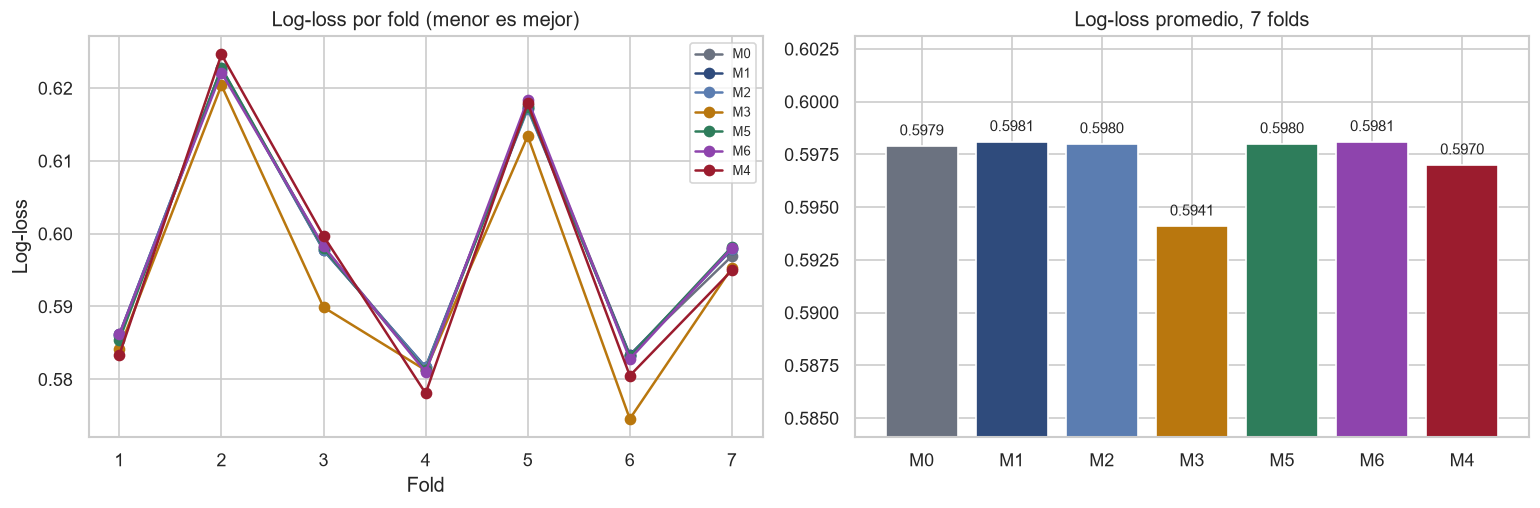

 RESUMEN — EXPERIMENTO CUOTAS MEJORADAS (aislado)
    log_loss  accuracy  roc_auc
M0    0.5979    0.6858   0.7352
M1    0.5981    0.6874   0.7352
M2    0.5980    0.6870   0.7352
M3    0.5941    0.6919   0.7404
M5    0.5980    0.6877   0.7353
M6    0.5981    0.6858   0.7350
M4    0.5970    0.6874   0.7344

variante  mejora_logloss_prom folds_mejora  p_Wilcoxon  dif_accuracy_pp  cumple_criterio
      M1              -0.0001       3 de 7      0.3223             0.15            False
      M2              -0.0001       3 de 7      0.6932             0.11            False
      M3               0.0038       7 de 7      0.0001             0.61             True
      M5              -0.0000       5 de 7      0.6573             0.19            False
      M6              -0.0001       3 de 7      0.3085             0.00            False
      M4               0.0010       4 de 7      0.8000             0.15            False


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for v, col in zip(V, ['#6B7280', '#2F4B7C', '#5B7DB1', '#B9770E', '#2E7D5B', '#8E44AD', '#9B1C2E']): ax[0].plot(fold_ll.index, fold_ll[v], 'o-', label=v, color=col)
ax[0].set_xlabel('Fold'); ax[0].set_ylabel('Log-loss'); ax[0].set_title('Log-loss por fold (menor es mejor)'); ax[0].legend(fontsize=8)
ax[1].bar(R.index, R['log_loss'], color=['#6B7280', '#2F4B7C', '#5B7DB1', '#B9770E', '#2E7D5B', '#8E44AD', '#9B1C2E']); ax[1].set_ylim(R['log_loss'].min() - .01, R['log_loss'].max() + .005)
for i, (v, x) in enumerate(R['log_loss'].items()): ax[1].text(i, x + .0005, f'{x:.4f}', ha='center', fontsize=9)
ax[1].set_title('Log-loss promedio, 7 folds'); plt.tight_layout(); plt.savefig('Imagenes/experimento_cuotas/comparacion.png', bbox_inches='tight', dpi=120); plt.show()
print('=' * 78); print(' RESUMEN — EXPERIMENTO CUOTAS MEJORADAS (aislado)'); print('=' * 78)
print(R[['log_loss', 'accuracy', 'roc_auc']].to_string()); print(); print(CR[['variante', 'mejora_logloss_prom', 'folds_mejora', 'p_Wilcoxon', 'dif_accuracy_pp', 'cumple_criterio']].to_string(index=False)); print('=' * 78)